In [1]:
import pandas as pd
df=pd.read_excel('cleaned_dataset.xlsx')

In [2]:
df

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"
...,...,...,...,...,...,...,...,...,...,...
8785,s8797,TV Show,Yunus Emre,Not Given,Turkey,2017-01-17,2016,TV-PG,2 Seasons,"International TV Shows, TV Dramas"
8786,s8798,TV Show,Zak Storm,Not Given,United States,2018-09-13,2016,TV-Y7,3 Seasons,Kids' TV
8787,s8801,TV Show,Zindagi Gulzar Hai,Not Given,Pakistan,2016-12-15,2012,TV-PG,1 Season,"International TV Shows, Romantic TV Shows, TV ..."
8788,s8784,TV Show,Yoko,Not Given,Pakistan,2018-06-23,2016,TV-Y,1 Season,Kids' TV


Step 1: Analyze rating categories.

In [3]:
df.isna().sum()

show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

In [ ]:
df.rating.unique() # The Column is clean.

<ArrowStringArray>
[   'PG-13',    'TV-MA',    'TV-PG',    'TV-14',    'TV-Y7',     'TV-Y',
       'PG',     'TV-G',        'R',        'G',    'NC-17',       'NR',
 'TV-Y7-FV',       'UR']
Length: 14, dtype: str

In [7]:
df['rating'].value_counts()

rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

Step 2: Identify the most common genres.

In [11]:
df.listed_in.unique()

<ArrowStringArray>
[                                                'Documentaries',
 'Crime TV Shows, International TV Shows, TV Action & Adventure',
                            'TV Dramas, TV Horror, TV Mysteries',
                            'Children & Family Movies, Comedies',
              'Dramas, Independent Movies, International Movies',
                                  'British TV Shows, Reality TV',
                                              'Comedies, Dramas',
          'Children & Family Movies, Comedies, Music & Musicals',
                                  'Dramas, International Movies',
                    'Children & Family Movies, Music & Musicals',
 ...
                      'British TV Shows, Docuseries, Reality TV',
                    'Anime Series, Crime TV Shows, TV Thrillers',
        'Classic & Cult TV, Kids' TV, Spanish-Language TV Shows',
       'Romantic TV Shows, Spanish-Language TV Shows, TV Dramas',
                            'TV Action & Adventure, 

In [12]:
top_genres = df['listed_in'].str.split(', ').explode().value_counts().head(10)
print(top_genres)

listed_in
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


Step 3: Compare ratings across content types.

In [13]:
rating_comparison = pd.crosstab(df['type'], df['rating'])
print(rating_comparison)

rating    G  NC-17  NR   PG  PG-13    R  TV-14  TV-G  TV-MA  TV-PG  TV-Y  \
type                                                                       
Movie    41      3  75  287    490  797   1427   126   2062    540   131   
TV Show   0      0   4    0      0    2    730    94   1143    321   175   

rating   TV-Y7  TV-Y7-FV  UR  
type                          
Movie      139         5   3  
TV Show    194         1   0  


In [ ]:
# Define the mapping dictionary
age_mapping = {
    'G': 'Kids', 'TV-Y': 'Kids', 'TV-Y7': 'Kids', 'TV-Y7-FV': 'Kids', 'TV-G': 'Kids', 'PG': 'Kids', 'TV-PG': 'Kids',
    'PG-13': 'Teens', 'TV-14': 'Teens',
    'R': 'Adults', 'NC-17': 'Adults', 'TV-MA': 'Adults',
    'NR': 'Other', 'UR': 'Other'
}

# Create a new column for the age category
df['age_category'] = df['rating'].map(age_mapping)

# Create the new crosstab
age_crosstab = pd.crosstab(df['type'], df['age_category'])
print(age_crosstab)

age_category  Adults  Kids  Other  Teens
type                                    
Movie           2862  1269     78   1917
TV Show         1145   785      4    730


Step 4: Create interactive visualizations.

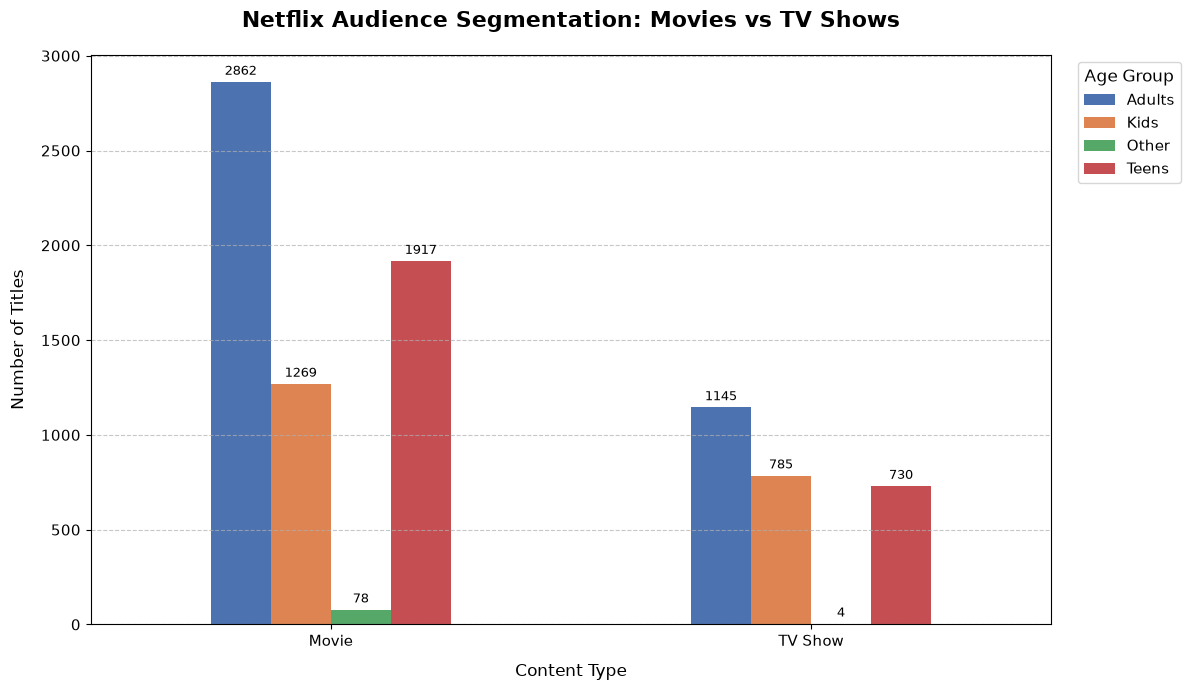

In [20]:
import matplotlib.pyplot as plt

# 1. Create the grouped bar chart (we don't write stacked=True so bars are side-by-side)
# 'age_crosstab' is the name of the table you created in the previous step
ax = age_crosstab.plot(kind='bar', figsize=(12, 7), rot=0, 
                       color=['#4C72B0', '#DD8452', '#55A868', '#C44E52'])

# 2. Set the title and axis labels
plt.title('Netflix Audience Segmentation: Movies vs TV Shows', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Content Type', fontsize=12, labelpad=10)
plt.ylabel('Number of Titles', fontsize=12, labelpad=10)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

# 3. Place the legend on the right side
plt.legend(title='Age Group', title_fontsize='12', fontsize='11', 
           bbox_to_anchor=(1.02, 1), loc='upper left')

# 4. Add grid lines to the background
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 5. Add the value labels on top of each bar (Very important for reporting!)
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontsize=9)

# 6. Display the plot
plt.tight_layout()
plt.show()

Step 5: Present audience insights

Age Group Mapping (Methodology):
To analyze audience targeting, the original rating categories were grouped into four distinct segments:

Kids (Family/Children): G, TV-Y, TV-Y7, TV-Y7-FV, TV-G, PG, TV-PG

Teens (Young Adults): PG-13, TV-14

Adults (Mature): R, NC-17, TV-MA

Other (Unrated): NR, UR (These were kept separate to avoid skewing the main audience segments).



Business Insights:

Based on the rating analysis, Netflix's content strategy reveals distinct audience targeting patterns. Adults represent the largest audience segment for both Movies and TV Shows, indicating that mature content (TV-MA, R, PG-13) is the primary focus. However, there is a notable difference between formats: Movies are heavily skewed towards Adults and Teens, while TV Shows maintain a more balanced distribution, with Kids and Teens holding a substantial share. This suggests that Netflix strategically uses Movies to cater to mature audiences, while utilizing TV Shows to attract and retain family and younger viewers. The negligible size of the 'Other' (NR/UR) category confirms that almost all content is clearly rated for specific age groups.